# From Degree to Employment: Early-Career Outcomes of Data and AI Graduates
## Milestone 3 – EDA, baseline model and modeling pipeline

**Group_13**

**Group members:** Souchitra Vongsomphou · Hrayr Kostanyan · Paulo Alves de Oliveira Junior · William Conlon

**Data:** NSCG 2023 public use file (NCSES/NSF), cleaned in Milestone 2 (`Milestone2_Group13.ipynb` writes `nscg_data/nscg_clean.csv`).

### Table of contents
1. [Project question](#1.-Project-question)
2. [Exploratory data analysis (EDA)](#2.-Exploratory-data-analysis-(EDA))
   - [2.1 The cleaned table](#2.1-The-cleaned-table)
   - [2.2 Where the negatives come from](#2.2-Where-the-negatives-come-from)
   - [2.3 Outcome rate by each predictor](#2.3-Outcome-rate-by-each-predictor)
   - [2.4 The numeric predictors](#2.4-The-numeric-predictors)
   - [2.5 Relationships between predictors](#2.5-Relationships-between-predictors)
   - [2.6 Groups used for the fairness evaluation](#2.6-Groups-used-for-the-fairness-evaluation)
   - [2.7 What the EDA changed in our plan](#2.7-What-the-EDA-changed-in-our-plan)
3. [Baseline model](#3.-Baseline-model)
4. [Results](#4.-Results)
5. [The modeling pipeline](#5.-The-modeling-pipeline)
6. [Next steps and questions for our TF](#6.-Next-steps-and-questions-for-our-TF)
7. [Use of generative AI and outside resources](#7.-Use-of-generative-AI-and-outside-resources)

## 1. Project question

**Primary question.** Among 2018–2022 bachelor's and master's graduates in computer science, statistics, operations research and applied mathematics who were in the US labor force in February 2023 (NSCG 2023, n = 1,461), how well can information available at graduation predict holding a full-time job (35+ hours) that is closely or somewhat related to the degree, and which of these factors are most strongly associated with it?

**Secondary question.** Do master's graduates have a higher rate of full-time, degree-related employment than bachelor's graduates with similar backgrounds? (An association, not the causal value of the degree; costs are not observed.)

**How we will know it was answered.** On a stratified 20% test set, kept untouched until the final models, the best model is compared with a prevalence baseline using PR-AUC for the negative class (graduates *without* such a job), ROC-AUC and balanced accuracy, with bootstrap confidence intervals.

**What changed after the EDA.** The question itself is unchanged. The EDA (section 2.7) changed how we model it: graduation year is treated as a category, the two skewed numeric predictors are log-transformed, a redundant indicator is dropped, and the secondary question is sharpened, because the master's advantage comes mainly from fewer graduates working outside their field, not from lower unemployment.

**Recap of Milestone 2.** One row = one graduate. Response `y` = 1 for a full-time, degree-related job (1,240 graduates), 0 otherwise (221: unemployed, part-time, or full time in an unrelated job). Every column was checked: there are no truly blank values, skip codes were recoded rather than dropped, and only information known at graduation is used as a predictor. Survey weights (`weight`) turn sample rates into population rates; the Kish effective sample size is about 371.

## 2. Exploratory data analysis (EDA)

### 2.1 The cleaned table

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, balanced_accuracy_score, brier_score_loss,
                             confusion_matrix, precision_recall_curve, roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict, train_test_split
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

SEED = 109
BLUE, ORANGE, AQUA, YELLOW, INK2 = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#52514e"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae", "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK2, "figure.dpi": 110,
})

CLEAN = Path("nscg_data") / "nscg_clean.csv"
if not CLEAN.exists():
    raise FileNotFoundError(f"{CLEAN} not found: run Milestone2_Group13.ipynb first, "
                            "it downloads the NSCG file and writes the cleaned table.")
clean = pd.read_csv(CLEAN, index_col="row_id")
clean["risk"] = 1 - clean["y"]          # 1 = no full-time, degree-related job: the class we want to find

print(f"Cleaned table: {clean.shape[0]:,} rows x {clean.shape[1]} columns")
print(f"y = 1: {clean.y.sum():,}   y = 0: {clean.risk.sum():,}   "
      f"(y = 0 share {clean.risk.mean():.1%} unweighted, {np.average(clean.risk, weights=clean.weight):.1%} weighted)")
clean.head()

Cleaned table: 1,461 rows x 19 columns
y = 1: 1,240   y = 0: 221   (y = 0 share 15.1% unweighted, 21.6% weighted)


,y,outcome,weight,degree,field_group,grad_year,years_since_grad,us_school,age_at_grad,no_ba_record,years_ba_to_degree,ba_field_group,parent_ed,sex,race,born_us,salary,very_satisfied,risk
row_id,,,,,,,,,,,,,,,,,,,
151,1,"FT, degree-related",70.4637,Master's,CS,2020,3,1,30,0,7.0,Engineering,Below bachelor's,Female,Hispanic,US-born,92000.0,1.0,0
721,1,"FT, degree-related",2716.2845,Master's,CS,2018,5,1,24,0,4.0,Other field,Graduate,Male,Asian,Foreign-born,190550.0,0.0,0
1075,1,"FT, degree-related",24.3938,Master's,CS,2018,5,1,38,0,17.0,Other field,Graduate,Male,White,US-born,235000.0,0.0,0
1170,1,"FT, degree-related",159.9455,Master's,CS,2020,3,1,28,0,8.0,Computer/math,Graduate,Male,White,US-born,200000.0,0.0,0
1269,1,"FT, degree-related",356.0695,Master's,Stats/OR/Applied math,2018,5,1,29,0,9.0,Computer/math,Below bachelor's,Male,Hispanic,Foreign-born,101000.0,1.0,0


In [2]:
def weighted_rate(y, w):
    """Weighted share of y = 1 with an approximate 95% CI on the logit scale.
    The public file has no replicate weights, so the interval is approximate."""
    y, w = np.asarray(y, float), np.asarray(w, float)
    n, p = len(y), np.sum(w * y) / np.sum(w)
    se = np.sqrt(n / (n - 1) * np.sum(w**2 * (y - p) ** 2)) / np.sum(w)
    if 0 < p < 1:
        logit, se_logit = np.log(p / (1 - p)), se / (p * (1 - p))
        lo, hi = (1 / (1 + np.exp(-(logit + k * 1.96 * se_logit))) for k in (-1, 1))
    else:
        lo = hi = np.nan
    return p, lo, hi


LABELS = {"us_school": {0: "non-US school", 1: "US school"}}
ORDER = {"parent_ed": ["Below bachelor's", "Bachelor's", "Graduate", "Not applicable"]}


def rate_table(frame, col):
    """One row per group: size, negatives, Kish effective size and the weighted % with y = 1."""
    rows = []
    groups = frame.groupby(col)
    keys = ORDER.get(col, list(groups.groups))
    for group in keys:
        d = groups.get_group(group)
        group = LABELS.get(col, {}).get(group, group)
        p, lo, hi = weighted_rate(d.y, d.weight)
        rows.append({"variable": col, "group": str(group), "n": len(d), "y = 0": int(d.risk.sum()),
                     "n_eff": round(d.weight.sum() ** 2 / (d.weight ** 2).sum()),
                     "weighted %": 100 * p, "ci low": 100 * lo, "ci high": 100 * hi})
    out = pd.DataFrame(rows)
    out["small"] = (out["y = 0"] < 10) | (out["n_eff"] < 30)
    return out.round(1)


def dot_panel(ax, table, title, overall):
    """Weighted % with 95% CI per group; hollow dot = small group (fewer than 10 negatives or n_eff < 30)."""
    t = table.iloc[::-1].reset_index(drop=True)
    ax.axvline(overall, color="#b5b4ae", ls="--", lw=1)
    for i, r in t.iterrows():
        ax.plot([r["ci low"], r["ci high"]], [i, i], color=BLUE, lw=2)
        ax.plot(r["weighted %"], i, "o", ms=8, mec=BLUE, mew=2, mfc="white" if r.small else BLUE)
    ax.set_yticks(range(len(t)), [f"{g} (n={n})" for g, n in zip(t.group, t.n)])
    ax.set_xlim(0, 100)
    ax.set_ylim(-0.7, len(t) - 0.3 if len(t) > 2 else 2.3)   # keep two-group panels compact
    ax.set_title(title, loc="left", fontsize=10)


OVERALL = 100 * weighted_rate(clean.y, clean.weight)[0]
print(f"Overall weighted % with a full-time, degree-related job: {OVERALL:.1f}%")

Overall weighted % with a full-time, degree-related job: 78.4%


### 2.2 Where the negatives come from

Purpose: the response combines three different situations. Before modeling the binary response, we check how they differ by degree level, the comparison behind our secondary question.

outcome,"FT, degree-related (weighted %)","FT, not related (weighted %)",Part-time (weighted %),Unemployed (weighted %)
degree,,,,
Bachelor's,75.7,7.8,7.1,9.4
Master's,84.2,2.9,4.2,8.8


outcome,"FT, degree-related (n)","FT, not related (n)",Part-time (n),Unemployed (n)
degree,,,,
Bachelor's,611,55,45,42
Master's,629,12,42,25


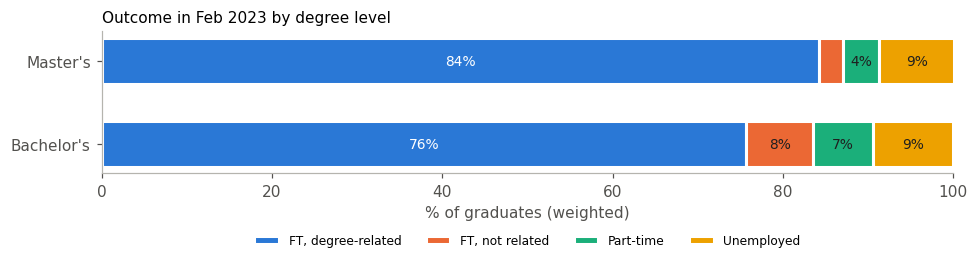

In [3]:
OUTCOMES = ["FT, degree-related", "FT, not related", "Part-time", "Unemployed"]
COLORS = [BLUE, ORANGE, AQUA, YELLOW]

totals = clean.pivot_table(index="degree", columns="outcome", values="weight", aggfunc="sum")
composition = (totals.div(totals.sum(axis=1), axis=0) * 100).reindex(columns=OUTCOMES).round(1)
counts = pd.crosstab(clean.degree, clean.outcome).reindex(columns=OUTCOMES)
display(composition.rename(columns=lambda c: c + " (weighted %)"))
display(counts.rename(columns=lambda c: c + " (n)"))

fig, ax = plt.subplots(figsize=(9, 2.8))
left = np.zeros(len(composition))
for outcome, color in zip(OUTCOMES, COLORS):
    vals = composition[outcome].values
    ax.barh(composition.index, vals, left=left, color=color, edgecolor="white", linewidth=2, label=outcome, height=0.55)
    for i, (l, v) in enumerate(zip(left, vals)):
        if v >= 4:
            ax.text(l + v / 2, i, f"{v:.0f}%", ha="center", va="center", fontsize=9,
                    color="white" if outcome == OUTCOMES[0] else "#1f1f1f")
    left += vals
ax.set_xlim(0, 100); ax.set_xlabel("% of graduates (weighted)")
ax.set_title("Outcome in Feb 2023 by degree level", loc="left", fontsize=10)
ax.legend(ncol=4, frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.35))
plt.tight_layout(); plt.show()

**What it shows.** Master's graduates are more likely to hold a full-time, degree-related job (about 84% vs 76%, weighted). The gap comes mostly from **fewer master's graduates working full time outside their field** (about 3% vs 8%) and fewer part-timers (about 4% vs 7%). Unemployment is almost the same for both groups (about 9%).

**How it affects our plan.**
* The secondary question is sharpened: the master's advantage looks like a better **match between degree and job**, not a lower chance of being unemployed.
* The model is trained on the binary response, but its errors will be broken down by outcome type (section 4.4), because a predictor can work for one kind of negative and not another.

### 2.3 Outcome rate by each predictor

Purpose: see which graduation-time predictors separate the two classes, how strongly, and which groups are too small to estimate reliably.

,variable,group,n,y = 0,n_eff,weighted %,ci low,ci high,small
0,degree,Bachelor's,753,142,224,75.7,68.8,81.5,False
1,degree,Master's,708,79,159,84.2,76.0,89.9,False
2,field_group,CS,1285,183,343,80.3,74.8,84.7,False
3,field_group,Stats/OR/Applied math,176,38,32,65.1,46.3,80.1,False
4,grad_year,2018,405,59,116,85.4,78.0,90.6,False
5,grad_year,2019,400,60,93,80.5,70.0,87.9,False
6,grad_year,2020,327,44,85,80.7,67.4,89.5,False
7,grad_year,2021,209,37,65,67.3,54.1,78.3,False
8,grad_year,2022,120,21,35,81.1,65.1,90.8,False
9,us_school,non-US school,43,13,15,43.7,23.0,66.9,True


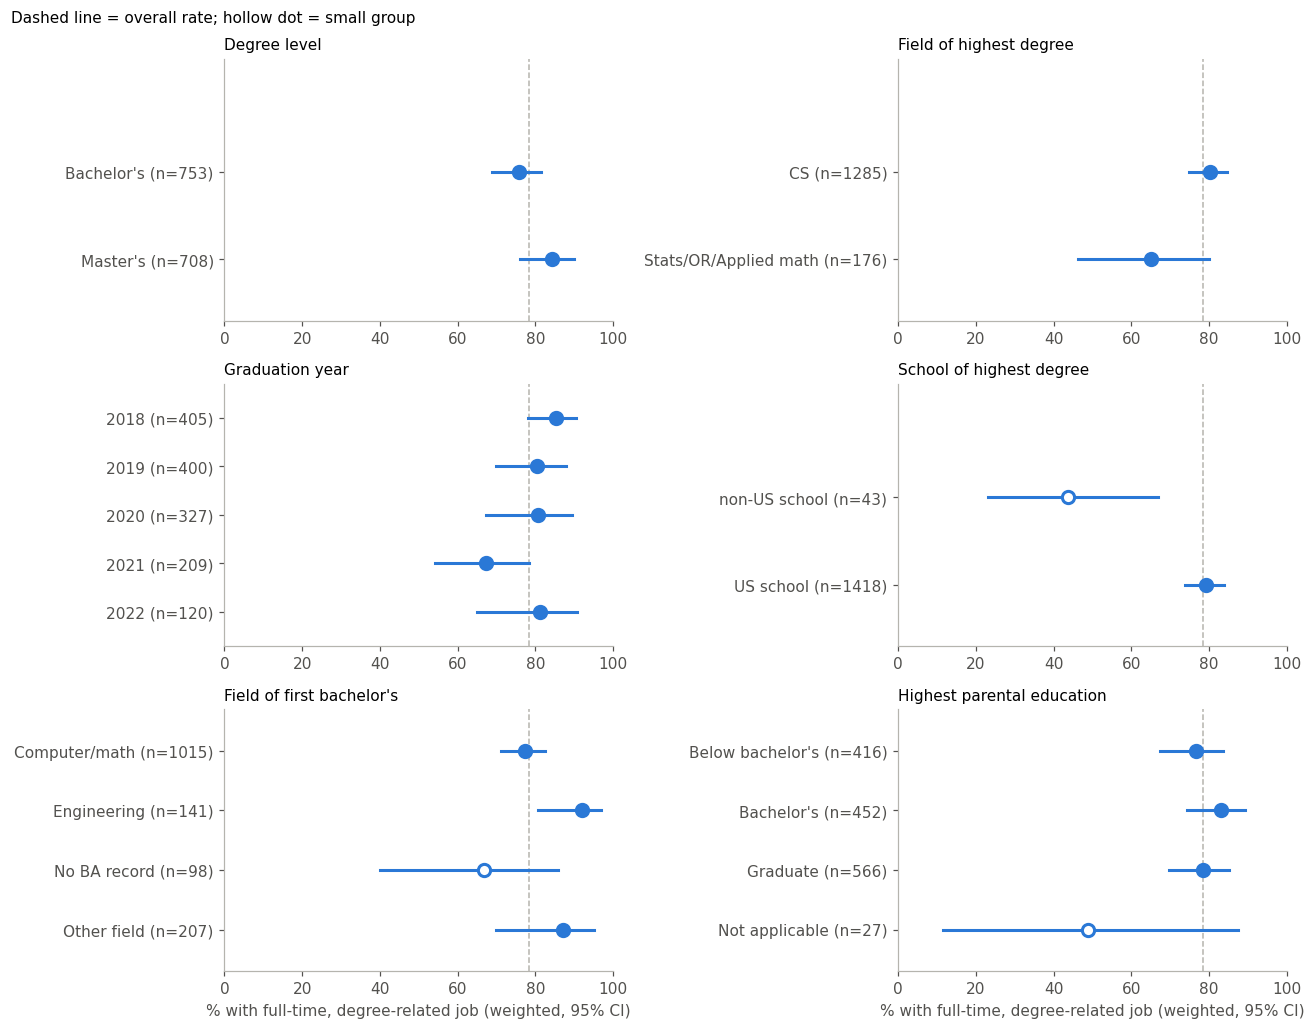

In [4]:
PREDICTORS = {"degree": "Degree level", "field_group": "Field of highest degree", "grad_year": "Graduation year",
              "us_school": "School of highest degree", "ba_field_group": "Field of first bachelor's",
              "parent_ed": "Highest parental education"}
pred_rates = pd.concat([rate_table(clean, c) for c in PREDICTORS], ignore_index=True)
display(pred_rates)

fig, axes = plt.subplots(3, 2, figsize=(12, 9.5))
for ax, (col, title) in zip(axes.ravel(), PREDICTORS.items()):
    dot_panel(ax, pred_rates[pred_rates.variable == col], title, OVERALL)
for ax in axes[-1]:
    ax.set_xlabel("% with full-time, degree-related job (weighted, 95% CI)")
fig.suptitle("Dashed line = overall rate; hollow dot = small group", x=0.01, ha="left", fontsize=10)
plt.tight_layout(); plt.show()

**What it shows.**
* **Degree level:** 76% (bachelor's) vs 84% (master's), with overlapping intervals: a real but modest difference.
* **Field:** computer science 80% vs statistics/OR/applied math 65%. The second group has only 176 graduates (effective n about 32), so its interval is wide.
* **Graduation year:** 2018–2020 and 2022 are all around 80–85%, but **2021 drops to about 67%**, the cohort that graduated into the pandemic labor market. The pattern is not a straight line.
* **US school:** the 43 graduates with a non-US highest degree have a much lower rate (about 44%), but it is a small group (effective n about 15).
* **Field of first bachelor's:** engineering (92%) and other fields (87%) are above computer/math (77%). Almost every bachelor's graduate is in computer/math, so this mostly separates master's graduates by their earlier field (see 2.5).
* **Parental education:** no clear ordering (77%, 83%, 79%). The "not applicable" group has 27 graduates and only 2 negatives, so it says nothing on its own.

**How it affects our plan.**
* **Graduation year is encoded as a category** (one indicator per cohort), not as a number, because the 2021 dip is not linear.
* All six predictors stay in the baseline; regularization decides how much each one counts. Small groups are flagged in every table and reported with intervals.
* The signals are modest, so we expect the model to beat the prevalence baseline only moderately.

### 2.4 The numeric predictors

Purpose: check the shape of the two numeric predictors and whether they differ between the classes.

,median (y=1),median (y=0),min,max,missing,skew (raw),skew (log1p)
age_at_grad,22.0,22.0,18.0,60.0,0.0,2.21,1.45
years_ba_to_degree,0.0,0.0,0.0,35.0,98.0,2.83,0.78


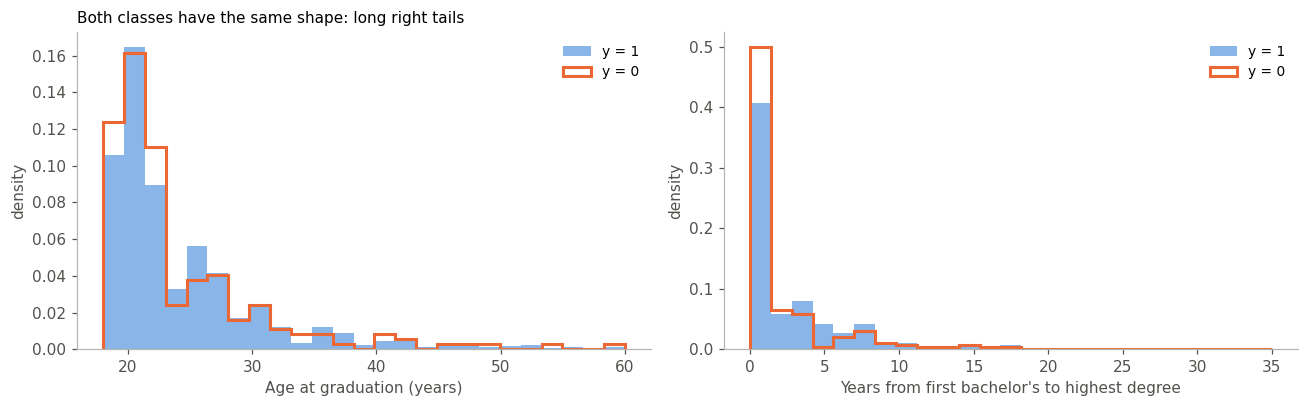

In [5]:
NUMERIC = {"age_at_grad": "Age at graduation (years)", "years_ba_to_degree": "Years from first bachelor's to highest degree"}

summary = pd.DataFrame({
    col: {"median (y=1)": clean.loc[clean.y == 1, col].median(), "median (y=0)": clean.loc[clean.y == 0, col].median(),
          "min": clean[col].min(), "max": clean[col].max(), "missing": int(clean[col].isna().sum()),
          "skew (raw)": clean[col].skew(), "skew (log1p)": np.log1p(clean[col]).skew()}
    for col in NUMERIC}).T.round(2)
display(summary)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, (col, label) in zip(axes, NUMERIC.items()):
    bins = np.histogram_bin_edges(clean[col].dropna(), bins=25)
    ax.hist(clean.loc[clean.y == 1, col].dropna(), bins=bins, density=True, color=BLUE, alpha=0.55, label="y = 1")
    ax.hist(clean.loc[clean.y == 0, col].dropna(), bins=bins, density=True, histtype="step", lw=2, color=ORANGE, label="y = 0")
    ax.set_xlabel(label); ax.set_ylabel("density")
    ax.legend(frameon=False, fontsize=9)
axes[0].set_title("Both classes have the same shape: long right tails", loc="left", fontsize=10)
plt.tight_layout(); plt.show()

**What it shows.** Both variables are strongly right-skewed (skew about 2.2 and 2.8): most graduates finish at 20–26 and go straight from bachelor's to their highest degree (0 years), with a long tail of older graduates and career changers. The two classes have the **same medians** (22 years; 0 years), so neither variable separates them much on its own. `years_ba_to_degree` is unknown for the 98 master's holders with no first-bachelor's record.

**How it affects our plan.**
* Both are **log-transformed** (`log1p`) and then standardized inside the pipeline; the transform reduces the skew (from 2.2 to 1.5 and from 2.8 to 0.8), so a few very old graduates or long gaps do not dominate a linear model.
* The 98 unknown values of `years_ba_to_degree` are filled with the training-fold median inside the pipeline. No extra missing-indicator is added, because the categorical level "No BA record" already marks exactly these 98 graduates.
* We expect a weak contribution from these two variables in a linear model; tree models (Milestone 4) can still pick up non-linear effects.

### 2.5 Relationships between predictors

Purpose: check for strongly related predictors, which make linear-model coefficients unstable and hard to interpret.

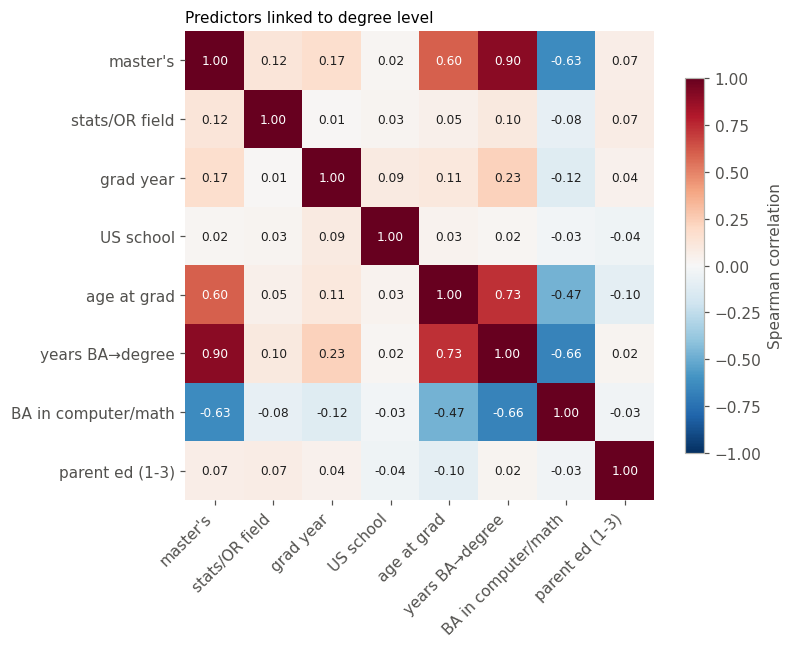

In [6]:
encoded = pd.DataFrame({
    "master's": (clean.degree == "Master's").astype(int),
    "stats/OR field": (clean.field_group != "CS").astype(int),
    "grad year": clean.grad_year,
    "US school": clean.us_school,
    "age at grad": clean.age_at_grad,
    "years BA→degree": clean.years_ba_to_degree,
    "BA in computer/math": (clean.ba_field_group == "Computer/math").astype(int),
    "parent ed (1-3)": clean.parent_ed.map({"Below bachelor's": 1, "Bachelor's": 2, "Graduate": 3}),
})
corr = encoded.corr(method="spearman")

fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(corr.iloc[i, j]) > 0.5 else "#1f1f1f")
ax.spines[:].set_visible(False)
fig.colorbar(im, ax=ax, shrink=0.8, label="Spearman correlation")
ax.set_title("Predictors linked to degree level", loc="left", fontsize=10)
plt.tight_layout(); plt.show()

**What it shows.** Degree level is tied to three other predictors: years from first bachelor's to highest degree (0.90; it is 0 for almost every bachelor's graduate), whether the first bachelor's was in computer/math (−0.63) and age at graduation (0.60). Graduation year, US school, field and parental education are nearly unrelated to the rest.

**How it affects our plan.**
* In a linear model the "degree effect" is shared among these four related predictors, so **no single coefficient should be read as the effect of a master's degree**. We use **regularized** logistic regression (L2 in the baseline, L1 and L2 later) to keep the coefficients stable.
* The indicator `no_ba_record` from Milestone 2 is **dropped from the features**: it duplicates the level "No BA record" of the first-bachelor's field.
* For the secondary question, the master's comparison is made both with and without these related predictors.

### 2.6 Groups used for the fairness evaluation

Purpose: sex, race/ethnicity and birthplace are not model features (Milestone 2, leakage and fairness table), but the final models' errors will be compared across these groups, so we check their size and base rates now.

,variable,group,n,y = 0,n_eff,weighted %,ci low,ci high,small
0,sex,Female,414,69,108,71.9,60.7,80.9,False
1,sex,Male,1047,152,265,80.7,74.6,85.6,False
2,race,Asian,530,67,138,81.7,73.4,87.9,False
3,race,Black,121,30,47,78.8,67.8,86.7,False
4,race,Hispanic,206,52,68,73.3,62.9,81.7,False
5,race,Other/multiple,50,11,14,51.3,26.7,75.3,True
6,race,White,554,61,142,81.3,71.8,88.1,False
7,born_us,Foreign-born,595,84,163,78.8,71.4,84.8,False
8,born_us,US-born,866,137,226,78.2,71.2,84.0,False


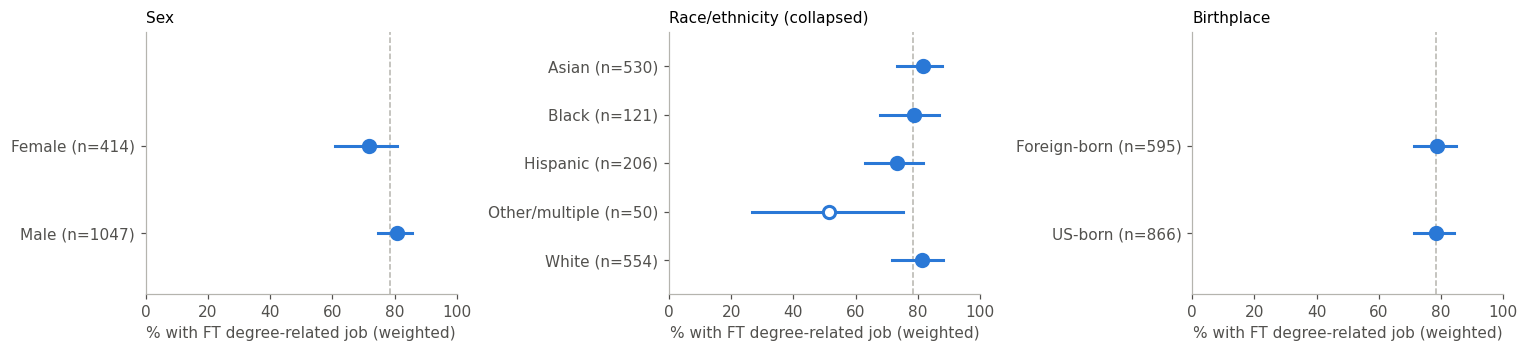

In [7]:
FAIRNESS = {"sex": "Sex", "race": "Race/ethnicity (collapsed)", "born_us": "Birthplace"}
fair_rates = pd.concat([rate_table(clean, c) for c in FAIRNESS], ignore_index=True)
display(fair_rates)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.3))
for ax, (col, title) in zip(axes, FAIRNESS.items()):
    dot_panel(ax, fair_rates[fair_rates.variable == col], title, OVERALL)
    ax.set_xlabel("% with FT degree-related job (weighted)")
plt.tight_layout(); plt.show()

**What it shows.** Women have a lower weighted rate than men (about 72% vs 81%), and Hispanic graduates (about 73%) are below Asian and White graduates (about 82% and 81%). US-born and foreign-born graduates are almost identical (about 78–79%). The "Other/multiple" group has only 50 graduates (effective n about 14), so its low rate (about 51%) is very uncertain.

**How it affects our plan.** Because base rates differ by sex and race/ethnicity, a model can make different kinds of errors for different groups even without using these columns. In Milestone 4 we will compare recall and false-positive rates for the negative class by sex, race/ethnicity and birthplace, and report "Other/multiple" with a warning about its size.

### 2.7 What the EDA changed in our plan

| Finding | Change |
|---|---|
| Master's advantage comes from fewer "full time, not related" and part-time outcomes, not lower unemployment | Secondary question sharpened; errors reported by outcome type |
| 2021 cohort dips; graduation year is not linear | Graduation year encoded as a category |
| Age at graduation and years between degrees are strongly skewed and weak alone | `log1p` transform + standardization inside the pipeline |
| Degree level is strongly related to years between degrees, first-bachelor's field and age | Regularized logistic regression; no causal reading of single coefficients |
| `no_ba_record` duplicates the "No BA record" level | Dropped from the features |
| Several small groups (non-US school, stats/OR, "Other/multiple", parental "not applicable") | Flagged in every table; intervals reported; no separate models for them |
| Signals are modest and the negative class is 15% | Main metric PR-AUC for the negative class against a prevalence baseline |

## 3. Baseline model

**Model: L2-regularized logistic regression** on all graduation-time predictors.
* **Why:** it is simple, fast and interpretable (odds ratios), it gives probabilities that can be thresholded, and it directly addresses the primary question (which factors are associated with the outcome). Regularization handles the related predictors found in 2.5.
* **What it predicts:** the probability that a graduate does **not** hold a full-time, degree-related job (`risk` = 1 − `y`), so the class we want to find is the positive class of every metric.
* **References for comparison:** a **prevalence model** (`DummyClassifier`, every graduate gets the training share of `risk`), the "mean model", and a **degree-only** logistic regression.

**Data.**
* All 1,461 graduates are used; no rows were removed.
* Stratified split (`random_state=109`): **80% training (1,168 graduates, 177 negatives)** and **20% test (293 graduates, 44 negatives)**. The test set is **not used in this milestone**; it is kept for the final comparison in Milestone 4.
* **Validation = 5-fold stratified cross-validation on the training set.** The reported results are out-of-fold predictions: every training graduate is predicted by a model that did not see them.

**Features (8 columns, 15 after encoding).** Degree level, field group, graduation year (category), field of first bachelor's, highest parental education, US school, age at graduation, years from first bachelor's to highest degree. Compared with Milestone 2 (9 predictors, 13 encoded columns), the `no_ba_record` indicator is dropped (EDA 2.5) and graduation year becomes a category (EDA 2.3), which gives 15 columns: about 12 training negatives per column. Sex, race/ethnicity and birthplace are excluded (fairness only), as is everything describing the 2023 job (leakage).

**Preprocessing (inside the pipeline, refit in every fold).**
* Categorical columns: one-hot encoding, first level dropped, unseen levels ignored.
* Numeric columns: median imputation (only `years_ba_to_degree` has missing values), `log1p`, standardization.
* US school: already 0/1, passed through.

**Tuning.** The inverse regularization strength `C` is chosen from 11 values between 0.001 and 100 by 5-fold stratified CV, maximizing PR-AUC (`average_precision`). Class weights are left equal: balanced class weights gave the same cross-validated PR-AUC (checked below), and the decision threshold is tuned separately (section 4.3).

**Metrics.** PR-AUC for the negative class (main), ROC-AUC, Brier score (probability accuracy), and balanced accuracy, recall and precision at a chosen threshold. Survey-weighted versions of PR-AUC and ROC-AUC are reported as a check.

In [8]:
CAT = ["degree", "field_group", "grad_year", "ba_field_group", "parent_ed"]
NUM = ["age_at_grad", "years_ba_to_degree"]
BIN = ["us_school"]

X = clean[CAT + NUM + BIN].astype({"grad_year": str})     # cohort as a category (EDA 2.3)
y = clean["risk"]

# X_test, y_test and w_test (test-set survey weights) are kept untouched until the final evaluation in Milestone 4.
X_train, X_test, y_train, y_test, w_train, w_test = train_test_split(
    X, y, clean["weight"], test_size=0.2, stratify=y, random_state=SEED)
outcome_train = clean.loc[X_train.index, "outcome"]

print(f"training: {len(X_train):,} graduates, {y_train.sum()} negatives ({y_train.mean():.1%})")
print(f"test (kept for Milestone 4): {len(X_test):,} graduates, {y_test.sum()} negatives ({y_test.mean():.1%})")

training: 1,168 graduates, 177 negatives (15.2%)
test (kept for Milestone 4): 293 graduates, 44 negatives (15.0%)


chosen C = 0.01   encoded features: 15


,C,mean CV PR-AUC,sd across folds
0,0.001,0.232,0.016
1,0.003,0.239,0.026
2,0.010,0.246,0.035
3,0.032,0.245,0.028
4,0.100,0.245,0.026
5,0.316,0.238,0.021
6,1.000,0.242,0.025
7,3.162,0.241,0.025
8,10.000,0.239,0.022
9,31.623,0.238,0.023


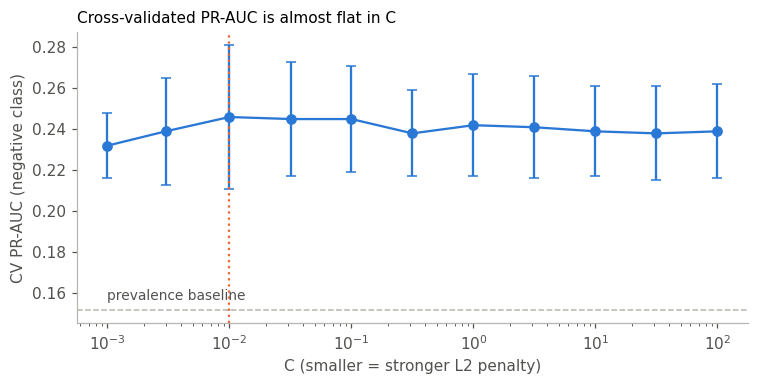

In [9]:
preprocess = ColumnTransformer([
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), CAT),
    ("num", make_pipeline(SimpleImputer(strategy="median"),
                          FunctionTransformer(np.log1p, feature_names_out="one-to-one"),
                          StandardScaler()), NUM),
    ("bin", "passthrough", BIN),
])
baseline = Pipeline([("prep", preprocess), ("logit", LogisticRegression(max_iter=5000))])

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)   # the same folds for every model
C_GRID = np.logspace(-3, 2, 11)
search = GridSearchCV(baseline, {"logit__C": C_GRID}, cv=skf, scoring="average_precision").fit(X_train, y_train)

cv_curve = pd.DataFrame({"C": C_GRID,
                         "mean CV PR-AUC": search.cv_results_["mean_test_score"],
                         "sd across folds": search.cv_results_["std_test_score"]}).round(3)
best_C = search.best_params_["logit__C"]
print(f"chosen C = {best_C:.3g}   encoded features: {len(search.best_estimator_['prep'].get_feature_names_out())}")
display(cv_curve)

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.errorbar(cv_curve.C, cv_curve["mean CV PR-AUC"], yerr=cv_curve["sd across folds"], marker="o", color=BLUE, capsize=3)
ax.axhline(y_train.mean(), color="#b5b4ae", ls="--", lw=1)
ax.text(C_GRID[0], y_train.mean() + 0.005, "prevalence baseline", fontsize=9, color=INK2)
ax.axvline(best_C, color=ORANGE, ls=":", lw=1.5)
ax.set_xscale("log"); ax.set_xlabel("C (smaller = stronger L2 penalty)"); ax.set_ylabel("CV PR-AUC (negative class)")
ax.set_title("Cross-validated PR-AUC is almost flat in C", loc="left", fontsize=10)
plt.tight_layout(); plt.show()

**Tuning result.** The CV curve is almost flat: every `C` gives a mean PR-AUC of about 0.23–0.25, well above the prevalence line (0.15), and the fold-to-fold spread is larger than the differences between values of `C`. The best value is a fairly strong penalty (`C` = 0.01). With so few negatives (about 35 per fold) the data cannot tell these values of `C` apart, so the exact choice matters little for the baseline.

**Class weights (Section 11).** A common correction for an imbalanced outcome is `class_weight="balanced"`, which gives each graduate of class *k* the weight N / (2 · N_k), so the 177 training negatives count as much in total as the 991 positives. We compare it with equal weights, tuning `C` for each on the same folds.

In [10]:
weight_rows = []
for class_weight in [None, "balanced"]:
    candidate = Pipeline([("prep", preprocess),
                          ("logit", LogisticRegression(max_iter=5000, class_weight=class_weight))])
    weight_search = GridSearchCV(candidate, {"logit__C": C_GRID}, cv=skf,
                                 scoring={"PR-AUC": "average_precision", "ROC-AUC": "roc_auc"},
                                 refit="PR-AUC").fit(X_train, y_train)
    best = weight_search.best_index_
    weight_rows.append({"class_weight": str(class_weight), "chosen C": weight_search.best_params_["logit__C"],
                        "CV PR-AUC": weight_search.cv_results_["mean_test_PR-AUC"][best],
                        "CV ROC-AUC": weight_search.cv_results_["mean_test_ROC-AUC"][best],
                        "sd of PR-AUC across folds": weight_search.cv_results_["std_test_PR-AUC"][best],
                        "sd of ROC-AUC across folds": weight_search.cv_results_["std_test_ROC-AUC"][best]})
pd.DataFrame(weight_rows).set_index("class_weight").round(3)

,chosen C,CV PR-AUC,CV ROC-AUC,sd of PR-AUC across folds,sd of ROC-AUC across folds
class_weight,,,,,
None,0.010,0.246,0.623,0.035,0.025
balanced,0.032,0.244,0.640,0.024,0.022


**What it shows.** Balanced class weights do not improve the baseline's main metric: the cross-validated PR-AUC is about 0.244 with balanced weights and 0.246 without, a difference far smaller than the spread between folds (about 0.02–0.04). ROC-AUC is a little higher with balanced weights (about 0.64 vs 0.62), but that difference is also within the fold-to-fold spread (about 0.02), and part of it comes from the different `C` chosen for each. For a logistic regression, reweighting the classes mainly shifts the intercept, so every predicted probability moves up but the **ranking** of graduates hardly changes, and PR-AUC and ROC-AUC measure the ranking. Its effect on decisions is the same as lowering the threshold, which we do directly in section 4.3.

**Decision.** The baseline keeps equal class weights. For the tree models in Milestone 4, where class weights and resampling change the rows each tree is trained on, we will compare no correction, class weights, undersampling, oversampling and SMOTE, with resampling done only inside the training folds (Section 11).

In [11]:
# Out-of-fold probabilities. Passing the GridSearchCV object re-tunes C inside each outer
# training fold, so the reported scores do not reuse the folds that chose C.
p_base = cross_val_predict(search, X_train, y_train, cv=skf, method="predict_proba")[:, 1]
p_prior = cross_val_predict(DummyClassifier(strategy="prior"), X_train, y_train, cv=skf, method="predict_proba")[:, 1]
degree_only = make_pipeline(OneHotEncoder(drop="first"), LogisticRegression())
p_degree = cross_val_predict(degree_only, X_train[["degree"]], y_train, cv=skf, method="predict_proba")[:, 1]
PREDICTIONS = {"prevalence (mean model)": p_prior, "degree only": p_degree, "baseline logistic (L2)": p_base}
print(f"baseline out-of-fold probabilities: min {p_base.min():.2f}, median {np.median(p_base):.2f}, max {p_base.max():.2f}")

baseline out-of-fold probabilities: min 0.03, median 0.15, max 0.59


## 4. Results

All results in this section are on the **validation data**: out-of-fold predictions for the 1,168 training graduates. The test set is untouched.

### 4.1 Scores against the reference models

In [12]:
def bootstrap_ci(metric, y_true, p, n_boot=1000):
    """95% percentile interval of a metric over bootstrap resamples of the graduates."""
    rng = np.random.default_rng(SEED)
    y_true = np.asarray(y_true)
    stats = []
    for _ in range(n_boot):
        i = rng.integers(0, len(y_true), len(y_true))
        stats.append(metric(y_true[i], p[i]))
    return np.percentile(stats, [2.5, 97.5])


rows = []
for name, p in PREDICTIONS.items():
    ap_lo, ap_hi = bootstrap_ci(average_precision_score, y_train, p)
    roc_lo, roc_hi = bootstrap_ci(roc_auc_score, y_train, p)
    rows.append({"model": name,
                 "PR-AUC": average_precision_score(y_train, p), "PR-AUC 95% CI": f"{ap_lo:.3f}–{ap_hi:.3f}",
                 "ROC-AUC": roc_auc_score(y_train, p), "ROC-AUC 95% CI": f"{roc_lo:.3f}–{roc_hi:.3f}",
                 "Brier": brier_score_loss(y_train, p),
                 "weighted PR-AUC": average_precision_score(y_train, p, sample_weight=w_train),
                 "weighted ROC-AUC": roc_auc_score(y_train, p, sample_weight=w_train)})
scores = pd.DataFrame(rows).set_index("model").round(3)
scores

,PR-AUC,PR-AUC 95% CI,ROC-AUC,ROC-AUC 95% CI,Brier,weighted PR-AUC,weighted ROC-AUC
model,,,,,,,
prevalence (mean model),0.151,0.129–0.175,0.496,0.451–0.541,0.129,0.210,0.493
degree only,0.171,0.144–0.203,0.556,0.509–0.601,0.127,0.251,0.577
baseline logistic (L2),0.214,0.180–0.263,0.631,0.588–0.675,0.127,0.292,0.658


**What it shows.**
* The **baseline logistic regression reaches a PR-AUC of about 0.21** (95% bootstrap interval about 0.18–0.26) against **0.15 for the prevalence model**, and a **ROC-AUC of about 0.63** (about 0.59–0.68) against 0.50. Its intervals exclude the prevalence values, so graduation-time information carries a real but **modest** signal.
* **Degree level alone** gets only part of the way (PR-AUC about 0.17, ROC-AUC about 0.56): the other predictors add information.
* The Brier score barely improves on the prevalence model (about 0.127 vs 0.129), because the predicted probabilities stay close to the base rate (mostly between 0.08 and 0.22).
* With survey weights the baseline scores are higher (PR-AUC about 0.29, where the weighted prevalence model scores about 0.21; ROC-AUC about 0.66), so the model ranks the population at least as well as the sample.

The intervals come from resampling the out-of-fold predictions; they do not include the variability of tuning, so they are slightly too narrow.

### 4.2 Precision–recall and ROC curves

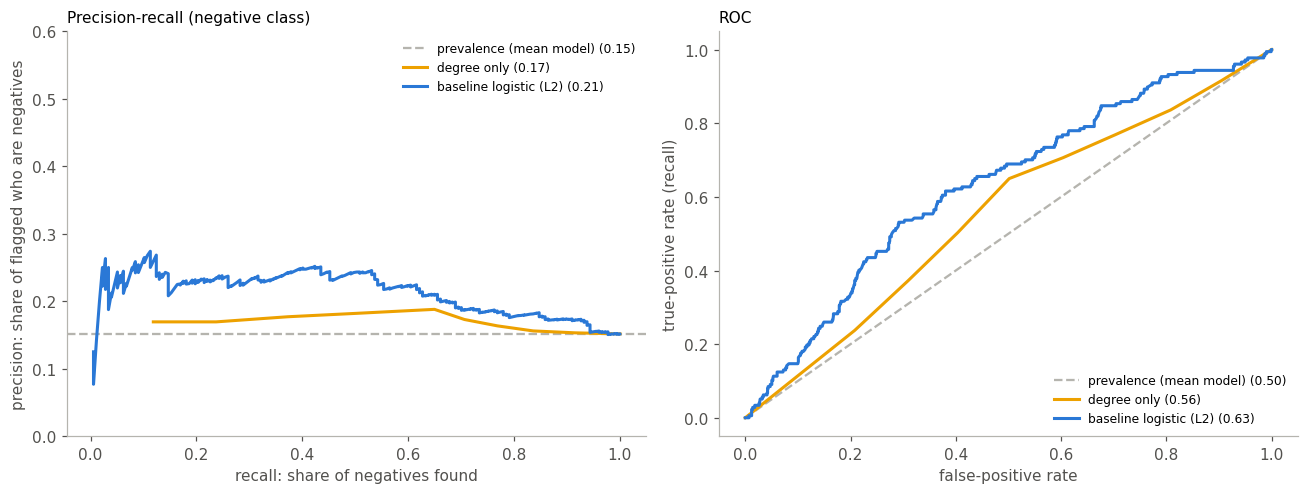

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
# The prevalence model gives every graduate the same probability: its PR "curve" is the
# horizontal line at the base rate and its ROC curve is the diagonal.
axes[0].axhline(y_train.mean(), color="#b5b4ae", ls="--", lw=1.5,
                label=f"prevalence (mean model) ({average_precision_score(y_train, p_prior):.2f})")
axes[1].plot([0, 1], [0, 1], color="#b5b4ae", ls="--", lw=1.5,
             label=f"prevalence (mean model) ({roc_auc_score(y_train, p_prior):.2f})")
for name, color in [("degree only", YELLOW), ("baseline logistic (L2)", BLUE)]:
    p = PREDICTIONS[name]
    prec, rec, _ = precision_recall_curve(y_train, p)
    keep = rec > 0                                  # drop the undefined point at zero recall
    axes[0].plot(rec[keep], prec[keep], color=color, lw=2, label=f"{name} ({average_precision_score(y_train, p):.2f})")
    fpr, tpr, _ = roc_curve(y_train, p)
    axes[1].plot(fpr, tpr, color=color, lw=2, label=f"{name} ({roc_auc_score(y_train, p):.2f})")
axes[0].set(xlabel="recall: share of negatives found", ylabel="precision: share of flagged who are negatives",
            ylim=(0, 0.6), title="Precision-recall (negative class)")
axes[1].set(xlabel="false-positive rate", ylabel="true-positive rate (recall)", title="ROC")
for ax, where in zip(axes, ["upper right", "lower right"]):
    ax.title.set_fontsize(10); ax.title.set_ha("left"); ax.title.set_x(0)
    ax.legend(frameon=False, fontsize=8, loc=where)
plt.tight_layout(); plt.show()

**What it shows.** The baseline's precision stays around 0.20–0.26 until it has found about 60% of the negatives, then falls to the 15% base rate; the degree-only model stays near 0.17–0.19. The baseline's ROC curve sits above the degree-only model and the diagonal almost everywhere, but far from the top-left corner. The model is useful for **ranking** graduates by risk, not for confidently identifying individuals.

### 4.3 Choosing a threshold: confusion matrix and balanced accuracy

A probability needs a threshold to become a decision. The default 0.5 flags almost nobody here (the highest predicted risk is under 0.6), so we compare several thresholds and choose the one that **maximizes F1 for the negative class** on the out-of-fold predictions (a balance of precision and recall, decided before looking at the results). In Milestone 4 the threshold chosen this way on the training data is applied once to the test set.

In [14]:
def confusion_at(threshold, p=p_base):
    """Counts and rates for the negative class at one threshold, out of fold on the training rows."""
    tn, fp, fn, tp = confusion_matrix(y_train, (p >= threshold).astype(int)).ravel()
    return {"threshold": threshold, "flagged": tp + fp, "negatives found (TP)": tp, "missed (FN)": fn,
            "false alarms (FP)": fp, "recall": tp / (tp + fn), "precision": tp / (tp + fp) if tp + fp else np.nan,
            "balanced accuracy": balanced_accuracy_score(y_train, (p >= threshold).astype(int))}


prec, rec, thr = precision_recall_curve(y_train, p_base)
f1 = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
best_threshold = thr[f1.argmax()]

table = pd.DataFrame([confusion_at(t) for t in (0.10, 0.15, best_threshold, 0.20, 0.30, 0.50)]).set_index("threshold")
display(table.round(3))

cm = pd.DataFrame(confusion_matrix(y_train, (p_base >= best_threshold).astype(int)),
                  index=["truly y = 1 (has the job)", "truly y = 0 (does not)"],
                  columns=["predicted y = 1", "predicted y = 0 (flagged)"])
print(f"chosen threshold (max F1 for the negative class): {best_threshold:.3f}")
cm

,flagged,negatives found (TP),missed (FN),false alarms (FP),recall,precision,balanced accuracy
threshold,,,,,,,
0.10000,954,164,13,790,0.927,0.172,0.565
0.15000,551,115,62,436,0.650,0.209,0.605
0.15773,383,94,83,289,0.531,0.245,0.620
0.20000,177,41,136,136,0.232,0.232,0.547
0.30000,49,11,166,38,0.062,0.224,0.512
0.50000,2,0,177,2,0.000,0.000,0.499


chosen threshold (max F1 for the negative class): 0.158


,predicted y = 1,predicted y = 0 (flagged)
truly y = 1 (has the job),702,289
truly y = 0 (does not),83,94


**What it shows.** At the chosen threshold (about 0.16) the baseline flags about a third of the graduates. It **finds about half of the negatives** (recall about 0.53, 94 of 177) and about **one in four flagged graduates really is a negative** (precision about 0.25, against 0.15 by chance). Balanced accuracy is about 0.62, against 0.50 for the prevalence model. Raising the threshold to 0.3 gives higher precision but finds very few negatives; 0.5 finds none.

These scores use the same out-of-fold predictions that chose the threshold, so they are slightly optimistic; the test set in Milestone 4 gives the honest version.

### 4.4 Where the baseline does well and where it does poorly

In [15]:
flagged = pd.Series(p_base >= best_threshold, index=X_train.index)
by_type = (flagged[y_train == 1].groupby(outcome_train[y_train == 1])
           .agg(["size", "mean"]).rename(columns={"size": "negatives", "mean": "share flagged (recall)"}))
display(by_type.round(3))

rows = []
for col in ["degree", "field_group"]:
    for group in X_train[col].unique():
        m = (X_train[col] == group).values
        rows.append({"group": f"{col} = {group}", "n": int(m.sum()), "negatives": int(y_train[m].sum()),
                     "base rate": y_train[m].mean(), "PR-AUC": average_precision_score(y_train[m], p_base[m]),
                     "ROC-AUC": roc_auc_score(y_train[m], p_base[m])})
pd.DataFrame(rows).set_index("group").round(3)

,negatives,share flagged (recall)
outcome,,
"FT, not related",53,0.660
Part-time,68,0.441
Unemployed,56,0.518


,n,negatives,base rate,PR-AUC,ROC-AUC
group,,,,,
degree = Master's,556,62,0.112,0.145,0.588
degree = Bachelor's,612,115,0.188,0.246,0.617
field_group = CS,1022,145,0.142,0.197,0.626
field_group = Stats/OR/Applied math,146,32,0.219,0.304,0.604


**What it shows.**
* **By kind of negative:** the baseline finds about two thirds of the graduates working **full time outside their field**, but only about half of the **unemployed** and fewer than half of the **part-time** workers. This matches the EDA (2.2): degree and field information mostly predicts a mismatch between degree and job, not unemployment or part-time work.
* **By degree:** among bachelor's graduates PR-AUC is about 0.25 (base rate about 0.19); among master's graduates it is about 0.15 (base rate about 0.11), and ROC-AUC is about 0.59. Within the master's group the model does little better than chance; much of its skill comes from **separating the two degree groups and ranking bachelor's graduates**.
* **By field:** the model ranks statistics/OR/applied-math graduates about as well as computer-science graduates (ROC-AUC about 0.60 vs 0.63); their PR-AUC is higher (about 0.30 vs 0.20) mainly because their base rate is higher (0.22 vs 0.14). With 32 negatives in that group, these scores are uncertain.

### 4.5 What the baseline learned

,odds ratio for risk (y = 0)
years_ba_to_degree,0.856
degree_Master's,0.895
grad_year_2020,0.943
us_school,0.947
ba_field_group_Engineering,0.960
ba_field_group_No BA record,0.971
parent_ed_Not applicable,0.981
grad_year_2019,0.990
parent_ed_Graduate,1.002
ba_field_group_Other field,1.009


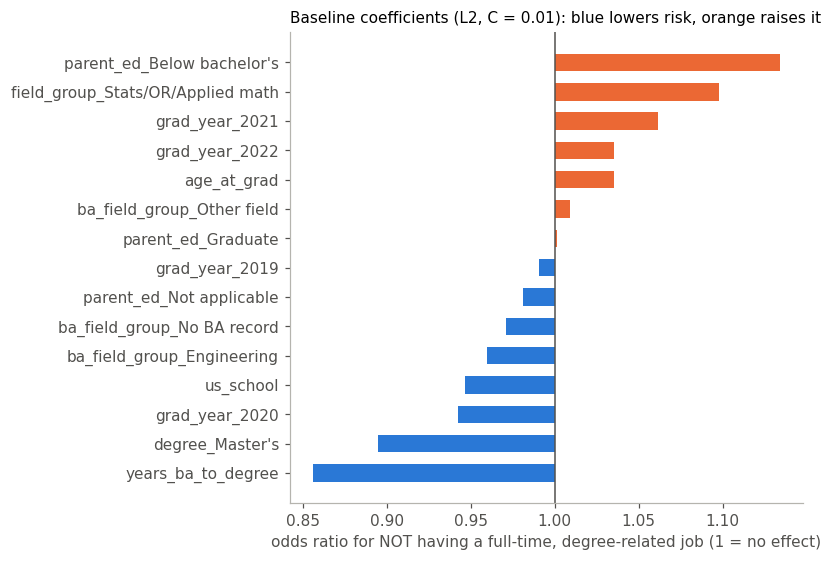

In [16]:
fitted = search.best_estimator_                          # refit on all training rows with the chosen C
names = fitted["prep"].get_feature_names_out()
odds = (pd.Series(np.exp(fitted["logit"].coef_[0]), index=names)
          .rename(lambda n: n.split("__", 1)[1]).sort_values())
display(odds.round(3).to_frame("odds ratio for risk (y = 0)"))

fig, ax = plt.subplots(figsize=(7.5, 5.2))
ax.barh(odds.index, odds.values - 1, left=1, color=[BLUE if v < 1 else ORANGE for v in odds.values], height=0.6)
ax.axvline(1, color=INK2, lw=1)
ax.set_xlabel("odds ratio for NOT having a full-time, degree-related job (1 = no effect)")
ax.set_title(f"Baseline coefficients (L2, C = {best_C:.3g}): blue lowers risk, orange raises it", loc="left", fontsize=10)
plt.tight_layout(); plt.show()

**What it shows.** With the strong penalty all odds ratios are shrunk toward 1, so their **ranking** matters more than their size. The features that lower the risk most are **more years between first bachelor's and highest degree** (per standard deviation of the log), a **master's degree** and graduating in **2020**; the features that raise it most are **parents without a bachelor's degree**, the **statistics/OR/applied-math field** and the **2021** cohort. A US school also lowers the risk, but its odds ratio is small (about 0.95) because only 43 graduates have a non-US degree and the penalty shrinks rare features the most. Degree level and years between degrees point the same way, as expected from their 0.90 correlation (2.5): together they carry the "master's" signal.

Because the predictors are related and the coefficients are penalized, these are **associations, not effects**. For the secondary question, Milestone 4 will report the master's odds ratio from a less-penalized model, with bootstrap intervals, with and without the related predictors.

### 4.6 Summary of the baseline and what we will change

| | Baseline (validation, out-of-fold) |
|---|---|
| PR-AUC, negative class | about 0.21 (prevalence 0.15) |
| ROC-AUC | about 0.63 (chance 0.50) |
| Balanced accuracy at the chosen threshold | about 0.62 (recall about 0.53, precision about 0.25) |

**Does well:** ranks graduates better than chance and better than degree level alone; finds most of the graduates working outside their field; separates bachelor's from master's risk.

**Does poorly:** predicted probabilities stay close to the base rate; weak within the master's group; misses about half of the unemployed and part-time graduates.

**Changes for the next models:**
1. **L1 and elastic-net logistic regression**, to see which predictors survive selection.
2. **Interactions** between degree level and the other predictors (for example field of first bachelor's and graduation year), since the EDA showed that several predictors matter mainly within one degree group.
3. **Tree models** (decision tree, random forest, gradient boosting), which find interactions and non-linear patterns without specifying them.
4. **Survey weights in training** (`sample_weight`) compared with unweighted training.
5. **Calibration** check of the predicted probabilities.

## 5. The modeling pipeline

From the cleaned table to the final evaluation:

1. **Input:** `nscg_clean.csv` from Milestone 2 (1,461 graduates). Response `risk` = 1 − `y`. Features: the 8 graduation-time predictors of section 3. Sex, race/ethnicity and birthplace are kept aside for the fairness evaluation; survey weights are kept aside for weighted training and reporting.
2. **Split once:** stratified 80/20 train/test split (`random_state=109`). The test set is used **only once**, in step 7.
3. **Preprocess inside a `Pipeline` + `ColumnTransformer`** (refit in every fold, so nothing leaks from validation rows):
   * categorical → `OneHotEncoder(drop="first", handle_unknown="ignore")` (no `drop` for tree models);
   * numeric → `SimpleImputer(strategy="median")` → `log1p` → `StandardScaler` (scaling only matters for the linear models and kNN);
   * optional `PolynomialFeatures(interaction_only=True)` for degree-level interactions in the linear models.
4. **Train and tune each model** with `GridSearchCV`, 5-fold `StratifiedKFold`, scoring **PR-AUC for the negative class**:

| Model | Parameters to tune |
|---|---|
| Logistic regression, L2 (baseline) | `C` |
| Logistic regression, L1 / elastic net | `C`, `l1_ratio` |
| Logistic regression with degree interactions | `C` |
| k-nearest neighbors | `n_neighbors`, `weights` |
| Decision tree | `max_depth`, `min_samples_leaf` |
| Random forest | `n_estimators`, `max_features`, `min_samples_leaf` |
| Gradient boosting | `learning_rate`, `n_estimators`, `max_depth` |

   Each model is also fitted with and without `sample_weight` (survey weights), and with and without `class_weight="balanced"`. For the tree models we also compare random undersampling, oversampling and SMOTE (`imblearn` pipeline), applied only inside the training folds (Section 11).
5. **Compare models** on out-of-fold predictions of the training set: PR-AUC (main), ROC-AUC, Brier score, with bootstrap intervals. Choose the simplest model within one standard error of the best PR-AUC (the one-standard-error rule from Section 4).
6. **Choose the threshold** on the out-of-fold predictions of the chosen model, by the rule fixed in advance (maximum F1 for the negative class).
7. **Final evaluation on the test set, once:** PR-AUC, ROC-AUC and Brier score with bootstrap intervals; confusion matrix, balanced accuracy, recall and precision at the chosen threshold; unweighted and survey-weighted.
8. **Interpretation and fairness:** odds ratios (logistic models) and permutation importance (all models); recall and false-positive rate for the negative class by sex, race/ethnicity and birthplace, and by outcome type; the master's vs bachelor's comparison for the secondary question.

**Assumptions.**
* The 2023 cross-section is representative of how graduation-time information relates to early-career outcomes for these cohorts (no follow-up over time is available).
* Values imputed by NCSES for item non-response are treated as observed (roughly missing at random).
* Survey weights are treated as fixed; without replicate weights, intervals ignore the survey design and are approximate.
* Results are associations: degree level, field and the other predictors are not randomly assigned.

## 6. Next steps and questions for our TF

| Member | Next step (Milestone 4) |
|---|---|
| Souchitra | L1 / elastic-net logistic regression and degree interactions |
| Hrayr | Tree models: decision tree, random forest, gradient boosting |
| Paulo | Survey weights in training, calibration, bootstrap intervals |
| William | Fairness evaluation by group and the master's vs bachelor's comparison |

**Questions for our TF.**
1. Our baseline is modest (PR-AUC about 0.21 vs 0.15). Is "graduation-time information predicts this outcome only weakly" an acceptable main finding if the final models do not improve much?
2. Should the final models be trained with the survey weights, or should the weights be used only for evaluation and reporting?
3. Is maximum F1 for the negative class a reasonable rule for choosing the threshold, or should we fix a target recall?

## 7. Use of generative AI and outside resources

* **Generative AI:** Claude (Anthropic), used through the Claude desktop app, November 2026, to draft and debug code for the EDA, the baseline pipeline and the evaluation, and to suggest wording for the explanations. Every cell was run on the real data, and the code, numbers and conclusions were checked and edited by the group, who take full responsibility for them.
* **Data:** National Center for Science and Engineering Statistics. National Survey of College Graduates, 2023 Public Use File. <https://ncses.nsf.gov/explore-data/microdata/national-survey-college-graduates>
* **Course materials:** CS1090A Sections 3–7 (one-hot encoding, pipelines and `ColumnTransformer`, cross-validation and the one-standard-error rule, regularization, logistic regression, thresholds and ROC curves) and Lecture 10 (missingness and imputation).